In [1]:
import pandas as pd

In [2]:
raw_file_path = "../data_raw/CMO-Historical-Data-Monthly.xlsx"
raw_prices = pd.read_excel(raw_file_path, sheet_name="Monthly Prices", header=None)
raw_prices.head(8)

,0,1,2,3,4,5,6,7,8,9,...,62,63,64,65,66,67,68,69,70,71
0,World Bank Commodity Price Data (The Pink Sheet),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"monthly prices in nominal US dollars, 1960 to ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,(monthly series are available only in nominal ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"Updated on November 03, 2026",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,"Crude oil, average","Crude oil, Brent","Crude oil, Dubai","Crude oil, WTI","Coal, Australian","Coal, South African **","Natural gas, US","Natural gas, Europe","Liquefied natural gas, Japan",...,Aluminum,"Iron ore, cfr spot",Copper,Lead,Tin,Nickel,Zinc,Gold,Platinum,Silver
5,NaN,($/bbl),($/bbl),($/bbl),($/bbl),($/mt),($/mt),($/mmbtu),($/mmbtu),($/mmbtu),...,($/mt),($/dmtu),($/mt),($/mt),($/mt),($/mt),($/mt),($/troy oz),($/troy oz),($/troy oz)
6,1960M01,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,715,206,2180,1631,261,35,84,0.9
7,1960M02,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,728,204,2180,1631,245,35,84,0.9


In [3]:
raw_prices.shape

(808, 72)

In [4]:
column_names = [str(name).strip() for name in raw_prices.iloc[4]]
column_names[0] = "date"
units_lookup = pd.DataFrame({
    "commodity": column_names[1:],
    "unit": raw_prices.iloc[5, 1:].values
})
units_lookup.head()

,commodity,unit
0,"Crude oil, average",($/bbl)
1,"Crude oil, Brent",($/bbl)
2,"Crude oil, Dubai",($/bbl)
3,"Crude oil, WTI",($/bbl)
4,"Coal, Australian",($/mt)


In [5]:
prices = raw_prices.iloc[6:].copy()
prices.columns = column_names
prices = prices.reset_index(drop=True)
prices.head(3)

,date,"Crude oil, average","Crude oil, Brent","Crude oil, Dubai","Crude oil, WTI","Coal, Australian","Coal, South African **","Natural gas, US","Natural gas, Europe","Liquefied natural gas, Japan",...,Aluminum,"Iron ore, cfr spot",Copper,Lead,Tin,Nickel,Zinc,Gold,Platinum,Silver
0,1960M01,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,715,206,2180,1631,261,35,84,0.9
1,1960M02,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,728,204,2180,1631,245,35,84,0.9
2,1960M03,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,685,210,2174,1631,249,35,84,0.9


In [6]:
for commodity_column in prices.columns[1:]:
    prices[commodity_column] = pd.to_numeric(prices[commodity_column], errors="coerce")
prices.isna().sum().sort_values(ascending=False).head(8)

Rice, Viet Namese 5%    538
Sunflower oil           510
Rapeseed oil            505
Rubber, TSR20 **        468
Banana, Europe          444
Palm kernel oil         432
Sawnwood, Cameroon      372
Rice, Thai 25%          316
dtype: int64

In [7]:
duplicate_dates = prices["date"].duplicated().sum()
print("Duplicate dates:", duplicate_dates)
print("Table size:", prices.shape)

Duplicate dates: 0
Table size: (802, 72)


In [8]:
prices["date"] = pd.to_datetime(prices["date"].str.replace("M", "-") + "-01")

prices["date"].head(3)

0   1960-01-01
1   1960-02-01
2   1960-03-01
Name: date, dtype: datetime64[ns]

In [9]:
selected_columns = {
    "Rice, Thai 5%": "Rice",
    "Wheat, US HRW": "Wheat",
    "Maize": "Maize",
    "Sugar, world": "Sugar",
    "Palm oil": "Palm_Oil",
    "Coconut oil": "Coconut_Oil",
    "Tea, Kolkata": "Tea",
    "Rubber, RSS3": "Rubber",
}
commodity_prices = prices[["date"] + list(selected_columns.keys())].rename(columns=selected_columns)
commodity_prices = commodity_prices.set_index("date")

commodity_prices.tail(3)

,Rice,Wheat,Maize,Sugar,Palm_Oil,Coconut_Oil,Tea,Rubber
date,,,,,,,,
2026-08-01,471.0,330.0,224.0,0.38,1132,1981,2.85,2.73
2026-09-01,482.0,347.0,239.6,0.41,1180,2079,2.53,2.75
2026-10-01,489.0,317.0,226.5,0.43,1120,2029,2.55,2.83


In [10]:
print(commodity_prices.isna().sum())
print(commodity_prices.index.min(), "to", commodity_prices.index.max())

Rice           0
Wheat          0
Maize          0
Sugar          0
Palm_Oil       0
Coconut_Oil    0
Tea            0
Rubber         0
dtype: int64
1960-01-01 00:00:00 to 2026-10-01 00:00:00


In [11]:
commodity_prices.to_csv("../data_clean/commodity_prices_clean.csv")
units_lookup.to_csv("../data_clean/units_lookup.csv", index=False)
print("Saved")

Saved


In [12]:
yearly_average = commodity_prices.groupby(commodity_prices.index.year).mean()
yearly_average.tail(6).round(2)

,Rice,Wheat,Maize,Sugar,Palm_Oil,Coconut_Oil,Tea,Rubber
date,,,,,,,,
2021,458.25,315.26,259.53,0.39,1130.42,1636.50,2.83,2.07
2022,436.75,429.98,318.80,0.41,1276.00,1634.67,2.83,1.81
2023,553.67,340.44,252.66,0.52,886.50,1075.33,2.44,1.58
2024,588.42,268.69,190.60,0.45,963.50,1518.75,2.81,2.28
2025,407.83,243.35,203.20,0.37,1006.83,2480.25,2.63,2.18
2026,444.40,295.85,215.76,0.35,1130.00,2130.10,2.59,2.59


In [13]:
yoy_change_pct = commodity_prices.pct_change(periods=12) * 100
latest_yoy = yoy_change_pct.iloc[-1].round(1).sort_values(ascending=False)
latest_yoy

Rubber         41.5
Rice           37.4
Wheat          37.3
Sugar          26.5
Maize          14.3
Palm_Oil        7.9
Tea           -10.8
Coconut_Oil   -20.3
Name: 2026-10-01 00:00:00, dtype: float64

In [14]:
monthly_change_pct = commodity_prices.pct_change() * 100
recent_10_years = monthly_change_pct.loc["2016-11-01":]
volatility = recent_10_years.std().round(2).sort_values(ascending=False)
volatility

Tea            17.89
Coconut_Oil     7.99
Rubber          7.04
Palm_Oil        6.65
Sugar           6.09
Wheat           5.94
Maize           5.77
Rice            5.32
dtype: float64

In [15]:
extreme_moves = pd.DataFrame({
    "Biggest monthly rise %": recent_10_years.max().round(1),
    "Biggest monthly fall %": recent_10_years.min().round(1),
})
extreme_moves

,Biggest monthly rise %,Biggest monthly fall %
Rice,16.1,-11.2
Wheat,24.5,-16.8
Maize,18.0,-14.4
Sugar,17.8,-21.2
Palm_Oil,16.8,-29.6
Coconut_Oil,29.5,-15.9
Tea,87.2,-22.8
Rubber,19.3,-18.1


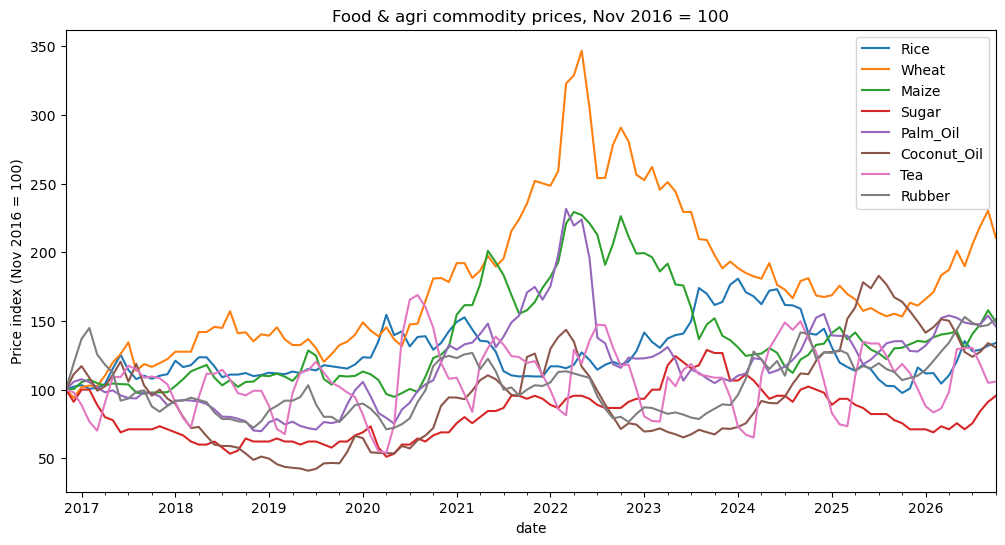

In [16]:
import matplotlib.pyplot as plt
last_10_years_prices = commodity_prices.loc["2016-11-01":]
indexed_prices = last_10_years_prices / last_10_years_prices.iloc[0] * 100
indexed_prices.plot(figsize=(12, 6), title="Food & agri commodity prices, Nov 2016 = 100")
plt.ylabel("Price index (Nov 2016 = 100)")
plt.savefig("../outputs/indexed_prices.png", dpi=150, bbox_inches="tight")
plt.show()

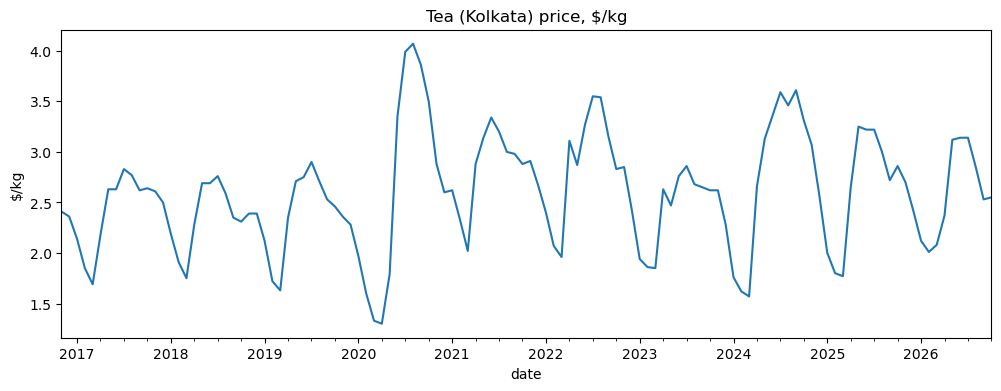

In [17]:
commodity_prices.loc["2016-11-01":, "Tea"].plot(figsize=(12, 4), title="Tea (Kolkata) price, $/kg")
plt.ylabel("$/kg")
plt.savefig("../outputs/tea_price.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:

tea_columns = ["Tea, Kolkata", "Tea, Colombo", "Tea, Mombasa", "Tea, avg 3 auctions"]
tea_compare = prices.set_index("date")[tea_columns]
tea_compare.loc["2020-02-01":"2020-10-01"]

,"Tea, Kolkata","Tea, Colombo","Tea, Mombasa","Tea, avg 3 auctions"
date,,,,
2020-02-01,1.60,3.35,2.13,2.36
2020-03-01,1.33,3.08,1.99,2.13
2020-04-01,1.30,3.66,2.11,2.36
2020-05-01,1.79,3.76,1.97,2.51
2020-06-01,3.35,3.30,1.86,2.84
2020-07-01,3.99,3.32,1.81,3.04
2020-08-01,4.07,3.37,2.00,3.15
2020-09-01,3.86,3.35,2.03,3.08
2020-10-01,3.50,3.51,1.98,3.00


In [19]:
tea_monthly_change = tea_compare.pct_change().loc["2016-11-01":] * 100
tea_monthly_change.std().round(2)

Tea, Kolkata           17.89
Tea, Colombo            6.92
Tea, Mombasa            5.20
Tea, avg 3 auctions     5.18
dtype: float64

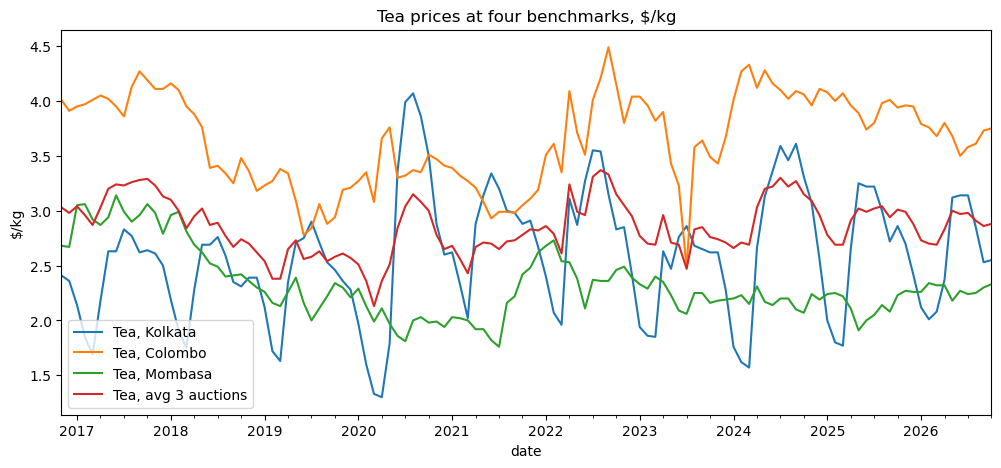

In [20]:
tea_compare.loc["2016-11-01":].plot(figsize=(12, 5), title="Tea prices at four benchmarks, $/kg")
plt.ylabel("$/kg")
plt.savefig("../outputs/tea_compare.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
commodity_prices["Tea_3Auction_Avg"] = tea_compare["Tea, avg 3 auctions"]

# Save the updated clean file (overwrites the old one, which is fine: it is our own output)
commodity_prices.to_csv("../data_clean/commodity_prices_clean.csv")
commodity_prices.shape

(802, 9)